# Area weighting changes the answer

**Atlas source reading copy · browser-network**

[Course guide](index.ipynb) · [Pinned original](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/0e32b2477ba5c0030985e25f1071d94cddabf130/content/06-area-means.ipynb)



Browser-only piplite prepares numpy, matplotlib, pandas, xarray and ipywidgets. Calculations use earthlab.py and original synthetic arrays, not observations or real Digital Twin outputs. Optional widget controls need the source frontend; static figures and numerical results provide alternatives. Real DestinE accounts, Polytope/Data Lake services, GRIB/netCDF decoding and HPC remain explicit source/native continuations. No credentials or service requests are required for these defaults.

**Provenance:** `content/06-area-means.ipynb` at `0e32b2477ba5c0030985e25f1071d94cddabf130`; original SHA-256 `6adb5bb73b84af89fe61ac496f7ec616d64af9af53376c8d101c4e467872a14b`. Original code MIT; original prose, generated numerical data and cleared artwork CC BY 4.0, with attribution and Atlas adaptation notice. Official DestinE references/datasets are linked context, not copied inputs.

**Verification:** imported by static inspection; saved upstream outputs cleared. Runtime compatibility is separate from executed verification. See the course guide for dependencies, excluded assets, aliases and original credits.


![Original abstract globe and synthetic weather streamlines](assets/splash.png)

# Area weighting changes the answer

**Lesson 06 · Original synthetic data · Independent educational project**

## Objectives

Calculate cosine-weighted means; test conservation for a constant field.

[Previous](05-labelled-arrays.ipynb) · [Notebook source](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/content/06-area-means.ipynb) · [Next](07-climate.ipynb)

[Open this notebook in JupyterLite](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/lab/index.html?path=06-area-means.ipynb) — public deployment pending until verified. For a local build, open the matching filename from the Lab file browser.

Run every code cell in order. The first run in JupyterLite downloads browser packages; it needs an internet connection. No account or credentials are used. The interactive visual lessons use ipywidgets, and the gallery provides additional live controls.

## Prepare the browser-sized environment

The shared `earthlab.py` helper lives beside every notebook. The same source notebook is used by the book and Lab.

In [1]:
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "matplotlib", "pandas", "xarray", "ipywidgets"])
import numpy as np
import matplotlib.pyplot as plt
import earthlab as lab
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(lab.PROVENANCE)

Original synthetic teaching data; not observations or DestinE model output


## Worked experiment

Run this original experiment and inspect both its figure and numerical checks.

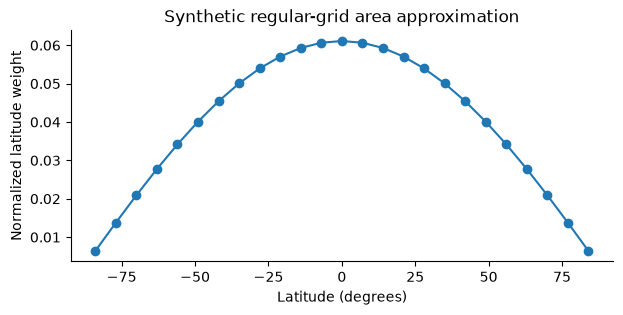

Weighted 276.33 K; unweighted 270.99 K


In [2]:
cube = lab.synthetic_cube()
field = cube["temperature"][0]
weighted = lab.global_mean(field, cube["lat"])
unweighted = field.mean()
weights = lab.area_weights(cube["lat"])
assert np.isclose(weights.sum(), 1)
assert np.isclose(lab.global_mean(np.ones_like(field)*7, cube["lat"]), 7)
assert weighted > unweighted
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(cube["lat"], weights, marker="o")
ax.set(xlabel="Latitude (degrees)", ylabel="Normalized latitude weight", title="Synthetic regular-grid area approximation")
plt.show()
print(f"Weighted {weighted:.2f} K; unweighted {unweighted:.2f} K")

## Exercise

Apply the same weights to precipitation. Explain why each latitude row has a different area even though it has the same number of grid points.

Add a code cell with your modification and at least one assertion that would catch an incorrect result. Keep the original experiment as a reference.

## Interpretation and limits

Cosine latitude is a regular-grid approximation. Accurate production calculations should use cell areas supplied with the model grid, particularly near poles and on irregular meshes.

**Check your reasoning:** identify one result the code establishes and one conclusion the demonstration cannot establish.

## References and provenance

- [Conceptual or software reference](https://destine.ecmwf.int/climate-digital-twin/) — linked for background; no text, external notebook code or data were copied.
- [Destination Earth initiative source index](https://github.com/destination-earth/DestinE).
- Generated arrays and equations: original project teaching material, CC BY 4.0; helper code: MIT. No authentic DestinE outputs or observational datasets are used.
- The abstract splash was generated for this project. See the repository's [attribution record](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/ATTRIBUTIONS.md).